# **"BioGen": Bacteria Toxicity Classifier**

### **The Scenario**
You are a computational biologist at "BioGen," a lab studying harmful bacteria strains. You need to classify bacterial samples as **"Safe"** or **"Toxic"** based on two automated measurements:

1.  **Colony Population:** Measured in **number of cells** (Large integer values, e.g., 50,000).
2.  **Toxin Secretion Level:** Measured in **micrograms** (Tiny decimal values, e.g., 0.5 µg).

You are using a **K-Nearest Neighbors (KNN)** algorithm to flag dangerous samples. However, your algorithm is failing to detect toxic samples, labeling them "Safe" even when their toxin levels are lethally high.

**Your Goal:** Use Feature Engineering and Linear Transformations ($x' = Wx$) to fix the scaling issue so the algorithm "sees" the toxin data.

---

### **The Data Problem**
Here is your training data. Notice the massive difference in scale between the two features.

| Sample ID | Population ($x_1$) | Toxin Level ($x_2$) | Label ($y$) |
| :--- | :--- | :--- | :--- |
| A | 50,000 | 0.1 | Safe |
| B | 50,100 | 0.2 | Safe |
| C | 49,900 | 0.1 | Safe |
| D | 52,000 | 0.1 | Safe |
| E | 50,000 | 0.9 | **Toxic** |
| F | 49,950 | 0.8 | **Toxic** |

**New Unknown Sample X:**
* **Population:** 50,100
* **Toxin Level:** 0.9 (Very High!)

Intuitively, Sample X has high toxin levels like Sample E, so it should be **Toxic**.
However, let's look at the math.

### **Knowledge Check**

**Question 1:** We calculate the Euclidean Distance between Sample X (50100, 0.9) and two neighbors:
* **Neighbor B (Safe):** (50100, 0.2)
* **Neighbor E (Toxic):** (50000, 0.9)

Which statement is true about the distances?

A) Distance to E is smaller because toxin levels match perfectly (0.9 vs 0.9).

**B) Distance to B is smaller because the Population difference is 0, whereas the Population difference to E is 100.**

C) The distances are exactly equal.

D) Toxin level is the dominant feature.

Distance B is smaller becuase according to L2 distance formula which is sqrt((x_2-x_1)^2 + (y_2-y_1)^2), the feature population dominates since scales of both features are different. 

### **Feature Transformation ($x' = Wx$)**

The Population numbers (thousands) are "drowning out" the Toxin numbers (decimals). We need to normalize this.
We can define a transformation $x' = Wx$ where $W$ is a scaling matrix.

**Question 2:** We want to scale **Population down by 100,000** and scale **Toxin Level up by 10**.
If input $x = \begin{bmatrix} \text{Pop} \\ \text{Toxin} \end{bmatrix}$, select the correct matrix $W$.

A) $W = \begin{bmatrix} 100,000 & 0 \\ 0 & 0.1 \end{bmatrix}$

**B) $W = \begin{bmatrix} 0.00001 & 0 \\ 0 & 10 \end{bmatrix}$**

C) $W = \begin{bmatrix} 10 & 0 \\ 0 & 0.00001 \end{bmatrix}$

D) $W = \begin{bmatrix} 1 & 1 \\ 0 & 1 \end{bmatrix}$

**B) $W = \begin{bmatrix} 0.00001 & 0 \\ 0 & 10 \end{bmatrix}$** This becuase this scales properly

In [10]:
import torch



x = torch.tensor([[50000, 50100, 49900, 52000, 50000, 49950], [0.1, 0.2, 0.1, 0.1, 0.9, 0.8]]).float()
x

tensor([[5.0000e+04, 5.0100e+04, 4.9900e+04, 5.2000e+04, 5.0000e+04, 4.9950e+04],
        [1.0000e-01, 2.0000e-01, 1.0000e-01, 1.0000e-01, 9.0000e-01, 8.0000e-01]])

In [11]:
w = torch.tensor([[0.00001, 0], [0, 10]])
w

tensor([[1.0000e-05, 0.0000e+00],
        [0.0000e+00, 1.0000e+01]])

In [13]:
x1 = w.matmul(x)
x1

tensor([[0.5000, 0.5010, 0.4990, 0.5200, 0.5000, 0.4995],
        [1.0000, 2.0000, 1.0000, 1.0000, 9.0000, 8.0000]])

### **Normalization Logic**

**Question 3:** Instead of manually guessing weights, a common technique is **Min-Max Normalization** (scaling to range [0, 1]).
Given a feature vector $x$ with minimum value $x_{min}$ and maximum $x_{max}$, which formula achieves this?

A) $x' = \frac{x - \mu}{\sigma}$

B) $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$

C) $x' = x \times W$

D) $x' = \log(x)$


***B) $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$***

### **Code Walkthrough: Visualizing the Shift**
Let's code this to see how the "Nearest Neighbors" change before and after transformation.

We will use scilit-learn's KNN Classifier for this exercise. Feel free to play around and try with Min-Max normalization scaling technique for both features.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

In [15]:
# 1. Setup Data: 2 Classes (Safe vs Toxic)
# Feature 0: Population (High Variance), Feature 1: Toxin (Low Variance)
# Let's generate 20 data points for better visualization
np.random.seed(42)

# Safe Samples: Pop ~50k, Toxin ~0.1
safe_pop = np.random.normal(50000, 200, 10)
safe_tox = np.random.normal(0.1, 0.05, 10)
safe_data = np.column_stack((safe_pop, safe_tox))

# Toxic Samples: Pop ~50k (Same!), Toxin ~0.9
toxic_pop = np.random.normal(45000, 200, 10)
toxic_tox = np.random.normal(0.9, 0.05, 10)
toxic_data = np.column_stack((toxic_pop, toxic_tox))

X_train = np.vstack((safe_data, toxic_data))
y_train = ['Safe']*10 + ['Toxic']*10

In [19]:
help(np.random.normal)

Help on method normal in module numpy.random.mtrand:

normal(loc=0.0, scale=1.0, size=None) method of numpy.random.mtrand.RandomState instance
    normal(loc=0.0, scale=1.0, size=None)

    Draw random samples from a normal (Gaussian) distribution.

    The probability density function of the normal distribution, first
    derived by De Moivre and 200 years later by both Gauss and Laplace
    independently [2]_, is often called the bell curve because of
    its characteristic shape (see the example below).

    The normal distributions occurs often in nature.  For example, it
    describes the commonly occurring distribution of samples influenced
    by a large number of tiny, random disturbances, each with its own
    unique distribution [2]_.

    .. note::
        New code should use the `~numpy.random.Generator.normal`
        method of a `~numpy.random.Generator` instance instead;
        please see the :ref:`random-quick-start`.

    Parameters
    ----------
    loc : float or a

In [18]:
safe_pop, safe_data, safe_tox

(array([50099.3428306 , 49972.34713977, 50129.53770762, 50304.60597128,
        49953.16932506, 49953.17260861, 50315.8425631 , 50153.48694583,
        49906.10512281, 50108.51200872]),
 array([[5.00993428e+04, 7.68291154e-02],
        [4.99723471e+04, 7.67135123e-02],
        [5.01295377e+04, 1.12098114e-01],
        [5.03046060e+04, 4.33598777e-03],
        [4.99531693e+04, 1.37541084e-02],
        [4.99531726e+04, 7.18856235e-02],
        [5.03158426e+04, 4.93584440e-02],
        [5.01534869e+04, 1.15712367e-01],
        [4.99061051e+04, 5.45987962e-02],
        [5.01085120e+04, 2.93848149e-02]]),
 array([0.07682912, 0.07671351, 0.11209811, 0.00433599, 0.01375411,
        0.07188562, 0.04935844, 0.11571237, 0.0545988 , 0.02938481]))

In [20]:
# New Unknown Sample X (High Toxin)
X_new = np.array([[50050, 0.85]])

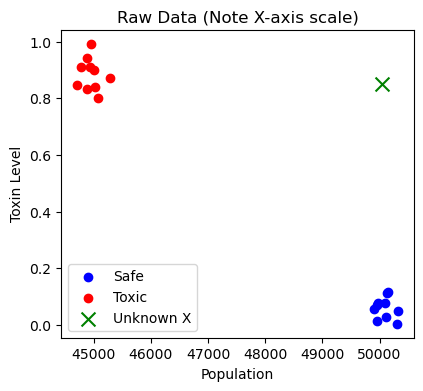

In [21]:
# 2. Visualize RAW Data
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(X_train[:10, 0], X_train[:10, 1], c='blue', label='Safe')
plt.scatter(X_train[10:, 0], X_train[10:, 1], c='red', label='Toxic')
plt.scatter(X_new[:, 0], X_new[:, 1], c='green', marker='x', s=100, label='Unknown X')
plt.title("Raw Data (Note X-axis scale)")
plt.xlabel("Population")
plt.ylabel("Toxin Level")
plt.legend()

In [22]:
# 3. Train KNN on RAW Data
knn_raw = KNeighborsClassifier(n_neighbors=3)
knn_raw.fit(X_train, y_train)
pred_raw = knn_raw.predict(X_new)
print(f"Prediction on RAW Data: {pred_raw[0]}")

Prediction on RAW Data: Safe


In [23]:
# 4. Apply Transformation Matrix W
# Scale Pop by 0.00001, Toxin by 10
W = np.array([
    [0.00001, 0],
    [0,      10]
])

X_transformed = X_train @ W.T
X_new_transformed = X_new @ W.T

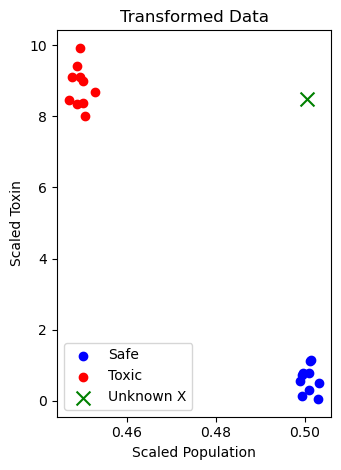

In [24]:
# 5. Visualize Transformed Data
plt.subplot(1, 2, 2)
plt.scatter(X_transformed[:10, 0], X_transformed[:10, 1], c='blue', label='Safe')
plt.scatter(X_transformed[10:, 0], X_transformed[10:, 1], c='red', label='Toxic')
plt.scatter(X_new_transformed[:, 0], X_new_transformed[:, 1], c='green', marker='x', s=100, label='Unknown X')
plt.title("Transformed Data")
plt.xlabel("Scaled Population")
plt.ylabel("Scaled Toxin")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# 6. Train KNN on TRANSFORMED Data
knn_trans = KNeighborsClassifier(n_neighbors=3)
knn_trans.fit(X_transformed, y_train)
pred_trans = knn_trans.predict(X_new_transformed)
print(f"Prediction on TRANSFORMED Data: {pred_trans[0]}")

Prediction on TRANSFORMED Data: Toxic


In [36]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
help(scaler)

Help on MinMaxScaler in module sklearn.preprocessing._data object:

class MinMaxScaler(sklearn.base.OneToOneFeatureMixin, sklearn.base.TransformerMixin, sklearn.base.BaseEstimator)
 |  MinMaxScaler(feature_range=(0, 1), *, copy=True, clip=False)
 |
 |  Transform features by scaling each feature to a given range.
 |
 |  This estimator scales and translates each feature individually such
 |  that it is in the given range on the training set, e.g. between
 |  zero and one.
 |
 |  The transformation is given by::
 |
 |      X_std = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
 |      X_scaled = X_std * (max - min) + min
 |
 |  where min, max = feature_range.
 |
 |  This transformation is often used as an alternative to zero mean,
 |  unit variance scaling.
 |
 |  `MinMaxScaler` doesn't reduce the effect of outliers, but it linearly
 |  scales them down into a fixed range, where the largest occurring data point
 |  corresponds to the maximum value and the smallest one corresponds t

In [38]:

X_transformed = scaler.fit_transform(X_train)
X_new_transformed = scaler.transform(X_new)
X_transformed

array([[0.9613448 , 0.07335298],
       [0.93867021, 0.073236  ],
       [0.96673598, 0.1090403 ],
       [0.99799375, 0.        ],
       [0.93524608, 0.00952983],
       [0.93524667, 0.06835085],
       [1.        , 0.04555647],
       [0.97101203, 0.11269743],
       [0.92684295, 0.05085898],
       [0.96298192, 0.02534593],
       [0.10321386, 0.87584541],
       [0.04281437, 1.        ],
       [0.05328805, 0.90560472],
       [0.        , 0.85277476],
       [0.03143718, 0.94790265],
       [0.05483763, 0.84452138],
       [0.00977557, 0.91685463],
       [0.06429256, 0.80714189],
       [0.02942832, 0.8390906 ],
       [0.04046051, 0.9162474 ]])

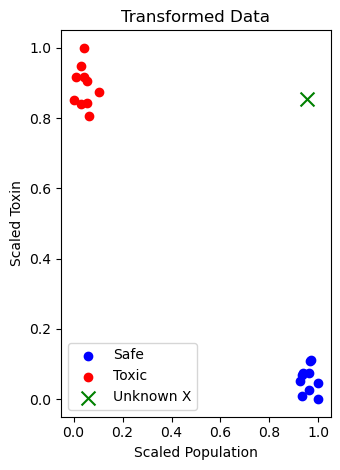

In [30]:
# 5. Visualize Transformed Data
plt.subplot(1, 2, 2)
plt.scatter(X_transformed[:10, 0], X_transformed[:10, 1], c='blue', label='Safe')
plt.scatter(X_transformed[10:, 0], X_transformed[10:, 1], c='red', label='Toxic')
plt.scatter(X_new_transformed[:, 0], X_new_transformed[:, 1], c='green', marker='x', s=100, label='Unknown X')
plt.title("Transformed Data")
plt.xlabel("Scaled Population")
plt.ylabel("Scaled Toxin")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# 6. Train KNN on TRANSFORMED Data
knn_trans = KNeighborsClassifier(n_neighbors=3)
knn_trans.fit(X_transformed, y_train)
pred_trans = knn_trans.predict(X_new_transformed)
print(f"Prediction on TRANSFORMED Data: {pred_trans[0]}")

Prediction on TRANSFORMED Data: Safe


In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
help(scaler)

Help on StandardScaler in module sklearn.preprocessing._data object:

class StandardScaler(sklearn.base.OneToOneFeatureMixin, sklearn.base.TransformerMixin, sklearn.base.BaseEstimator)
 |  StandardScaler(*, copy=True, with_mean=True, with_std=True)
 |
 |  Standardize features by removing the mean and scaling to unit variance.
 |
 |  The standard score of a sample `x` is calculated as:
 |
 |  .. code-block:: text
 |
 |      z = (x - u) / s
 |
 |  where `u` is the mean of the training samples or zero if `with_mean=False`,
 |  and `s` is the standard deviation of the training samples or one if
 |  `with_std=False`.
 |
 |  Centering and scaling happen independently on each feature by computing
 |  the relevant statistics on the samples in the training set. Mean and
 |  standard deviation are then stored to be used on later data using
 |  :meth:`transform`.
 |
 |  Standardization of a dataset is a common requirement for many
 |  machine learning estimators: they might behave badly if the
 |

In [33]:

X_transformed = scaler.fit_transform(X_train)
X_new_transformed = scaler.transform(X_new)

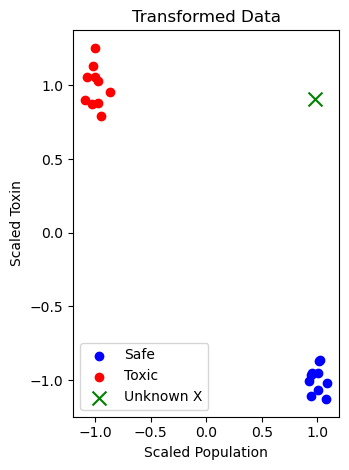

In [34]:
# 5. Visualize Transformed Data
plt.subplot(1, 2, 2)
plt.scatter(X_transformed[:10, 0], X_transformed[:10, 1], c='blue', label='Safe')
plt.scatter(X_transformed[10:, 0], X_transformed[10:, 1], c='red', label='Toxic')
plt.scatter(X_new_transformed[:, 0], X_new_transformed[:, 1], c='green', marker='x', s=100, label='Unknown X')
plt.title("Transformed Data")
plt.xlabel("Scaled Population")
plt.ylabel("Scaled Toxin")
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# 6. Train KNN on TRANSFORMED Data
knn_trans = KNeighborsClassifier(n_neighbors=3)
knn_trans.fit(X_transformed, y_train)
pred_trans = knn_trans.predict(X_new_transformed)
print(f"Prediction on TRANSFORMED Data: {pred_trans[0]}")

Prediction on TRANSFORMED Data: Safe
